# 02 — Technical replicates: how reproducible are wells within a plate?

Every community sits in **three wells on the same plate** (replicates never share a row,
never neighbours). 31 communities are also on **both** passage plates (5 and 6), in
triplicate on each, at re-randomised positions — so within-plate and between-plate
replicate differences both include position, and the excess of between- over
within-plate is the plate effect (`01_setup/README.md`).

**Depth decides what "reproducible" can mean.** Two perfect replicates sampled at 100
reads already differ by a Bray-Curtis (BC) of ~0.1 from counting alone; at 2000 reads by
~0.02. So every replicate distance here is shown next to the distance multinomial
sampling alone would give at the same depths (`composition.null_bray_curtis`, using the
pair's pooled composition as truth); the **excess** over that null is the
biological + technical (pipetting, Echo, position) variation.

Compositions use **member reads only** (foreign / unexplained reads are notebook 01's
subject). Wells need ≥ 30 member reads.

In [1]:
import sys, json
from pathlib import Path
QC_DIR = Path("/home/rl/scripts/karl/sequencing_experiments/community_assembly_experiments/20261026/02_qc")
sys.path.insert(0, str(QC_DIR))
import config                                   # paths; puts the shared libraries on sys.path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from community_qc import plots as P, composition as comp, io as cio
P.setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
OUT, FIG = config.OUT, config.FIG
TH = json.load(open(OUT / "q02_thresholds.json"))
lay = cio.load_layout(config.LAYOUT_CSV)
def savefig(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

mt = pd.read_csv(OUT / "q04_member_table.csv")
ws = pd.read_csv(OUT / "q04_well_summary.csv")
pairs = comp.replicate_pairs(mt, min_member_reads=30, seed=0)
pairs.groupby(["timepoint", "kind", "plate_a", "plate_b"]).size().rename("pairs").to_frame().T

timepoint            24h                               5d                  
kind      between_plates within_plate      between_plates within_plate     
plate_a               5            5    6              9            9    10
plate_b               6            5    6              10           9    10
pairs                155          280  124            164          130  280

## Summary (numbers reproduced below)

- **Replicate wells agree well, and better than the raw numbers on 6 and 9 suggest.** On
  the deep plates the median Bray-Curtis (BC) between replicate wells is **0.10–0.11**,
  against 0.02–0.03 from counting alone. So there is real well-to-well variation, but
  it is small: the same member dominates in 78–85% of replicate pairs, and 87–88% of
  members are either present (≥ 1%) in all three replicates or in none.
- On plates 6 and 9 the observed BC (~0.12) is mostly counting noise (null 0.07–0.09).
  **Rarefied to the same 60 reads, all four plates look alike** (BC 0.12–0.15).
- **No detectable plate effect.** For the 31 communities on both passage plates,
  between-plate distances are not larger than within-plate ones (24 h: 0.24 vs 0.22,
  p = 0.79; 5 d: 0.20 vs 0.17, p = 0.10). Power is limited: only 18–22 communities have
  ≥ 60 reads in enough wells, because one plate at each time point is shallow.
- **Replicates converge with time.** On culture plate 5, replicate BC drops from 0.18
  at 24 h to 0.12 at 5 d (p = 0.02); plate 6 goes the same way (n.s.). Communities lose
  members and settle on the same few survivors.

## 1. How many complete replicate sets are there?

In [2]:
ok = ws[(ws.well_type == "community")].assign(usable=lambda t: t.member >= 30)
per = ok.groupby(["plate", "timepoint", "community_id"]).usable.sum()
tab = per.groupby(level=[0, 1]).value_counts().unstack(fill_value=0).reindex(columns=[0, 1, 2, 3], fill_value=0)
tab.columns = [f"{c} of 3 usable" for c in tab.columns]
tab

,,0 of 3 usable,1 of 3 usable,2 of 3 usable,3 of 3 usable
plate,timepoint,,,,
5,24h,0,0,13,89
6,24h,13,21,40,28
9,5d,17,17,37,31
10,5d,0,0,13,89


## 2. Within-plate replicate distance vs. sampling noise

,,pairs,median_bc,median_null,median_excess,dominant_same,median_reads
plate_a,timepoint,,,,,,
5,24h,280,0.106,0.025,0.085,0.782,1475.0
6,24h,124,0.123,0.094,0.029,0.815,60.0
9,5d,130,0.118,0.066,0.051,0.815,93.0
10,5d,280,0.101,0.017,0.079,0.854,1736.5


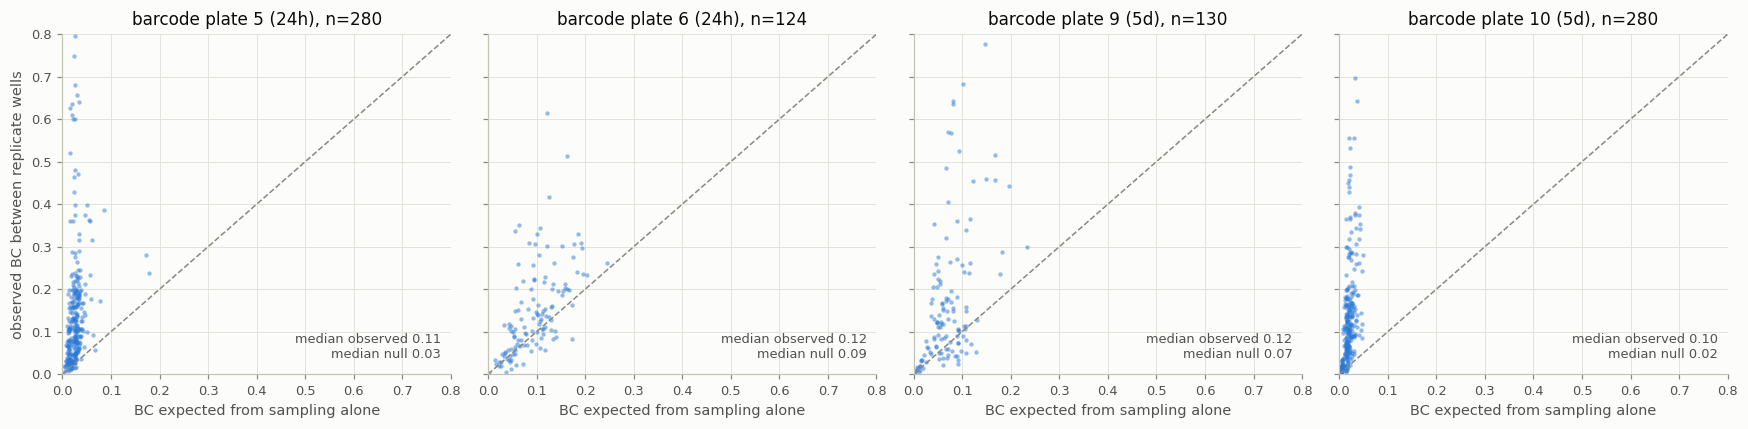

In [3]:
w = pairs[pairs.kind == "within_plate"]
fig, ax = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for k, (p, g) in enumerate(w.groupby("plate_a")):
    ax[k].scatter(g.null_bray_curtis, g.bray_curtis, s=8, alpha=.5, color=P.CAT[0], lw=0)
    ax[k].plot([0, 1], [0, 1], color=P.MUTED, lw=1, ls="--")
    tp = g.timepoint.iat[0]
    ax[k].set(title=f"barcode plate {p} ({tp}), n={len(g)}", xlabel="BC expected from sampling alone",
              xlim=(0, .8), ylim=(0, .8))
    ax[k].text(.78, .03, f"median observed {g.bray_curtis.median():.2f}\nmedian null {g.null_bray_curtis.median():.2f}",
               ha="right", va="bottom", fontsize=8.5, color=P.INK2)
ax[0].set_ylabel("observed BC between replicate wells")
fig.tight_layout(); savefig(fig, "02_within_plate_vs_null.png")
(w.groupby(["plate_a", "timepoint"])
  .agg(pairs=("bray_curtis", "size"), median_bc=("bray_curtis", "median"), median_null=("null_bray_curtis", "median"),
       median_excess=("excess_bray_curtis", "median"), dominant_same=("dominant_same", "mean"),
       median_reads=("reads_a", "median")).round(3))

Plates 6 and 9 sit at ~1/20 the depth of 5 and 10, so their raw BC is mostly counting
noise. To compare the four plates on equal terms, every well is **rarefied to the same
number of member reads** and the distances recomputed.

,,pairs,median_bc,median_null
plate,timepoint,,,
5,24h,278,0.150,0.107
6,24h,39,0.133,0.084
9,5d,75,0.117,0.078
10,5d,277,0.133,0.082


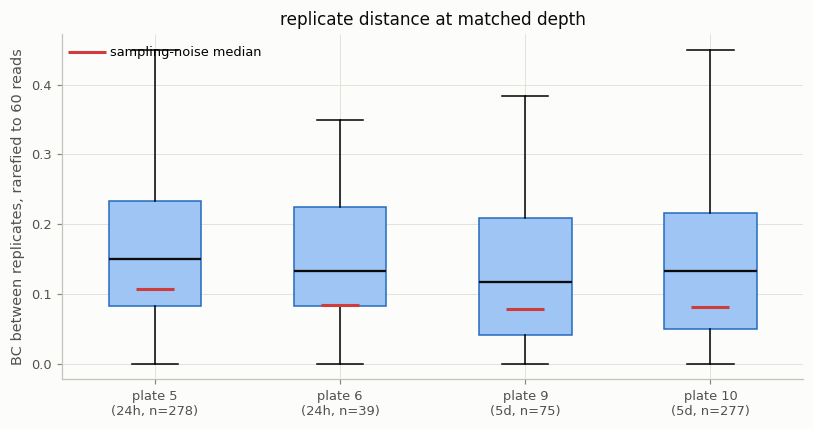

In [4]:
RARE = 60
rng = np.random.default_rng(1)
rows = []
mt_ok = mt[mt.member_reads >= RARE]
vec = {sid: g.set_index("strain").reads for sid, g in mt_ok.groupby("sample_id")}
meta = mt_ok.drop_duplicates("sample_id").set_index("sample_id")
for (cid, plate), g in meta.groupby(["community_id", "plate"]):
    ids = list(g.index)
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            a, b = vec[ids[i]], vec[ids[j]].reindex(vec[ids[i]].index).fillna(0)
            ra, rb = comp.rarefy(a.to_numpy(), RARE, rng), comp.rarefy(b.to_numpy(), RARE, rng)
            pooled = (ra / RARE + rb / RARE) / 2
            rows.append(dict(plate=plate, timepoint=g.timepoint.iat[0], community_id=cid, size=g["size"].iat[0],
                             bc=comp.bray_curtis(ra / RARE, rb / RARE),
                             null=comp.null_bray_curtis(pooled, RARE, RARE, rng)))
rare = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.5, 4))
order = [5, 6, 9, 10]
data = [rare[rare.plate == p].bc for p in order]
bp = ax.boxplot(data, widths=.5, patch_artist=True, showfliers=False, medianprops=dict(color=P.INK, lw=1.5))
for b in bp["boxes"]:
    b.set(facecolor=P.SEQ_STEPS[1], edgecolor=P.SEQ_STEPS[4])
nulls = [rare[rare.plate == p].null.median() for p in order]
ax.scatter(range(1, 5), nulls, marker="_", s=600, color=P.STATUS["critical"], zorder=3, label="sampling-noise median")
ax.set_xticks(range(1, 5), [f"plate {p}\n({rare[rare.plate==p].timepoint.iat[0]}, n={len(rare[rare.plate==p])})" for p in order])
ax.set(ylabel=f"BC between replicates, rarefied to {RARE} reads", title="replicate distance at matched depth")
ax.legend(loc="upper left")
fig.tight_layout(); savefig(fig, "02_rarefied_by_plate.png")
rare.groupby(["plate", "timepoint"]).agg(pairs=("bc", "size"), median_bc=("bc", "median"), median_null=("null", "median")).round(3)

## 3. What disagrees: dominant member, presence of minor members, size

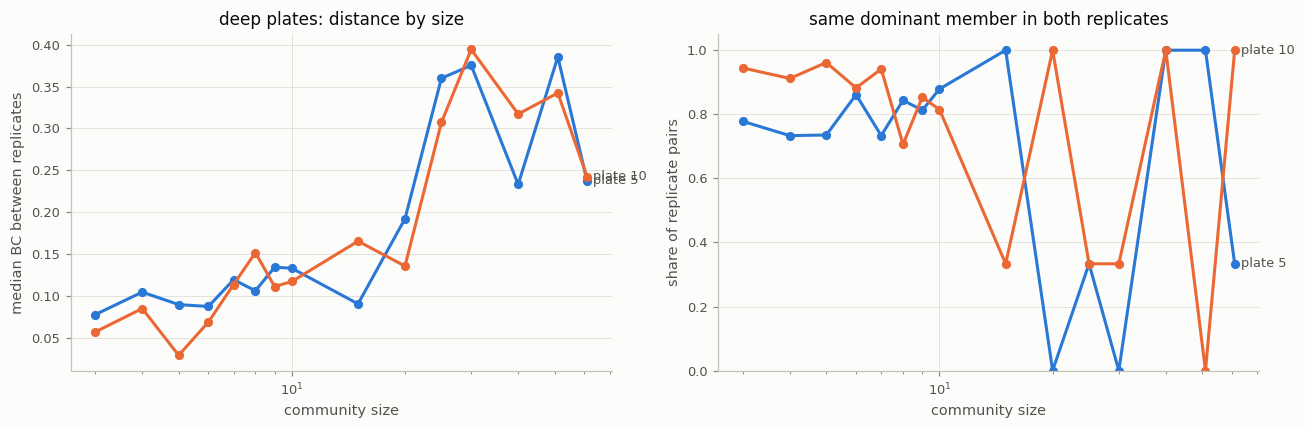

In [5]:
deep = w[w.plate_a.isin([5, 10])]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, (p, g) in enumerate(deep.groupby("plate_a")):
    s = g.groupby("size").agg(bc=("bray_curtis", "median"), ex=("excess_bray_curtis", "median"))
    ax[0].plot(s.index, s.bc, marker="o", color=P.CAT[k]); P.label_end(ax[0], s.index[-1], s.bc.iat[-1], f"plate {p}")
    d2 = g.groupby("size").dominant_same.mean()
    ax[1].plot(d2.index, d2, marker="o", color=P.CAT[k]); P.label_end(ax[1], d2.index[-1], d2.iat[-1], f"plate {p}")
ax[0].set(xscale="log", xlabel="community size", ylabel="median BC between replicates", title="deep plates: distance by size")
ax[1].set(xscale="log", xlabel="community size", ylabel="share of replicate pairs", ylim=(0, 1.05),
          title="same dominant member in both replicates")
fig.tight_layout(); savefig(fig, "02_by_size.png")

In [6]:
# presence/absence at >= 1%: do replicates keep the same members? (deep plates only: 1% is resolvable)
pres = mt[mt.plate.isin([5, 10]) & (mt.member_reads >= 300)].assign(on=lambda t: t.frac_members >= 0.01)
agree = (pres.groupby(["plate", "community_id", "strain"]).on.agg(["sum", "size"]).query("size == 3")
            ["sum"].groupby(level=0).value_counts().unstack(fill_value=0))
agree.columns = [f"present in {c}/3" for c in agree.columns]
agree["members scored"] = agree.sum(axis=1)
agree["consistent (0/3 or 3/3)"] = (agree.get("present in 0/3", 0) + agree.get("present in 3/3", 0)) / agree["members scored"]
agree.round(3)

,present in 0/3,present in 1/3,present in 2/3,present in 3/3,members scored,consistent (0/3 or 3/3)
plate,,,,,,
5,201,39,40,356,636,0.876
10,383,37,57,249,726,0.871


## 4. Examples: replicate compositions side by side

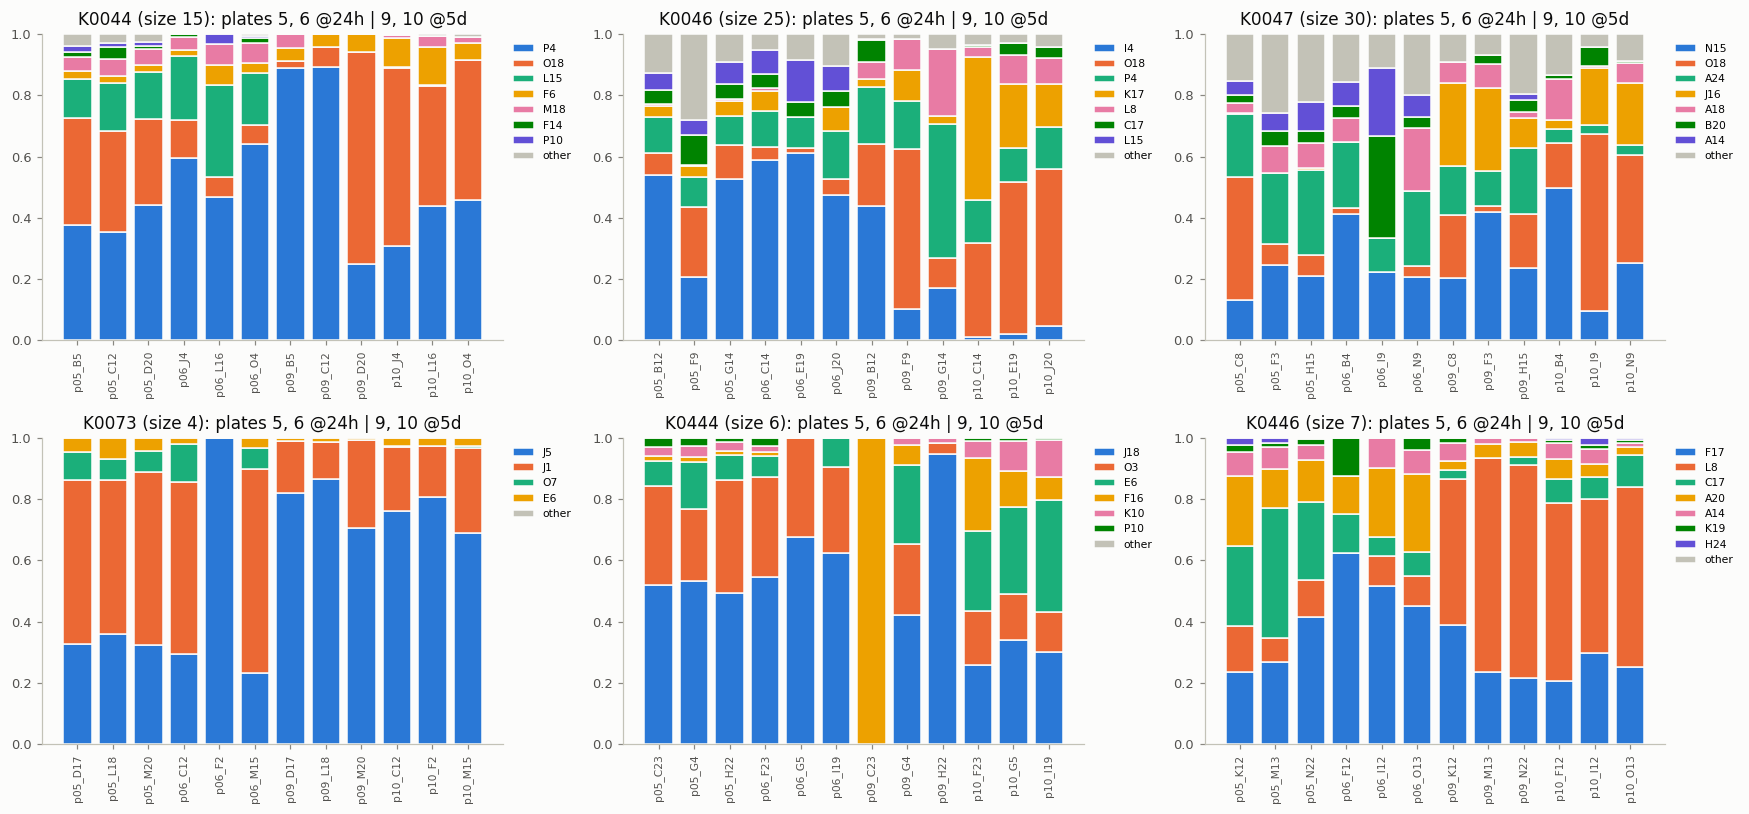

In [7]:
def stack(ax, sids, title):
    sub = mt[mt.sample_id.isin(sids)]
    strains = sub.groupby("strain").frac_members.mean().sort_values(ascending=False).index
    top = list(strains[:7])
    bottom = np.zeros(len(sids))
    for k, s in enumerate(top + ["other"]):
        if s == "other":
            v = np.array([sub[(sub.sample_id == i) & ~sub.strain.isin(top)].frac_members.sum() for i in sids])
            col = "#c3c2b7"
        else:
            v = np.array([sub[(sub.sample_id == i) & (sub.strain == s)].frac_members.sum() for i in sids])
            col = P.CAT[k]
        ax.bar(range(len(sids)), v, bottom=bottom, color=col, width=.8, label=s, edgecolor=P.SURFACE, lw=1)
        bottom += v
    ax.set_xticks(range(len(sids)), [i.replace("Plate", "p") for i in sids], rotation=90, fontsize=7)
    ax.set(ylim=(0, 1), title=title); ax.grid(False)
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))

shared = pd.read_csv(config.COMMUNITIES_CSV).query("passage_plates == '5 6'").community_id
ex = (pairs[(pairs.kind == "between_plates") & pairs.community_id.isin(shared)]
      .groupby("community_id").reads_a.size().sort_values(ascending=False).index[:6])
fig, axs = plt.subplots(2, 3, figsize=(16, 7.5))
for ax, cid in zip(axs.flat, ex):
    sids = sorted(mt[mt.community_id == cid].sample_id.unique(), key=lambda s: (int(s[5:7]), s))
    size = int(mt[mt.community_id == cid]["size"].iat[0])
    stack(ax, sids, f"{cid} (size {size}): plates 5, 6 @24h | 9, 10 @5d")
fig.tight_layout(); savefig(fig, "02_examples.png")

## 5. Between plates: the 31 communities on both passage plates

For each shared community and time point: the median distance between replicates on the
SAME plate vs. between the two plates. Depth differs by ~20x between the two plates at
each time point (24 h: 5 deep / 6 shallow; 5 d: 9 shallow / 10 deep), so this is done on
rarefied counts (same depth everywhere) — otherwise the shallow plate's counting noise
would masquerade as a plate effect.

kind,between,within
timepoint,,
24h,0.238,0.221
5d,0.200,0.171


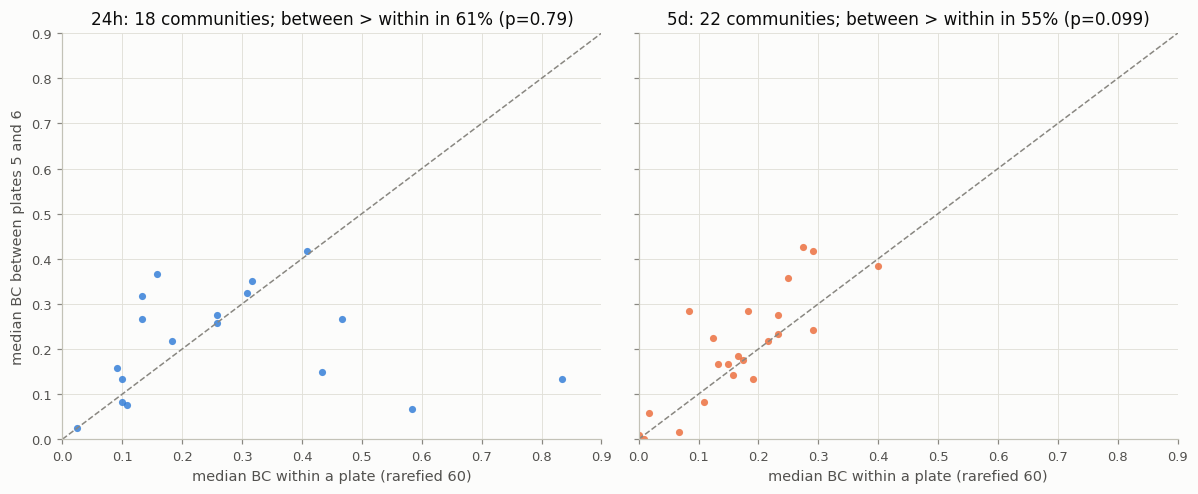

In [8]:
RARE = 60
rng = np.random.default_rng(2)
sh = mt[mt.community_id.isin(shared) & (mt.member_reads >= RARE)]
vec = {sid: g.set_index("strain").reads for sid, g in sh.groupby("sample_id")}
meta = sh.drop_duplicates("sample_id").set_index("sample_id")
rows = []
for (cid, tp), g in meta.groupby(["community_id", "timepoint"]):
    ids = list(g.index)
    rv = {i: comp.rarefy(vec[i].reindex(vec[ids[0]].index).fillna(0).astype(int).to_numpy(), RARE, rng) / RARE for i in ids}
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            kind = "within" if meta.at[ids[i], "plate"] == meta.at[ids[j], "plate"] else "between"
            rows.append(dict(community_id=cid, timepoint=tp, kind=kind, size=g["size"].iat[0],
                             bc=comp.bray_curtis(rv[ids[i]], rv[ids[j]])))
bp_ = pd.DataFrame(rows)
cmp_ = bp_.groupby(["community_id", "timepoint", "kind"]).bc.median().unstack()
cmp_ = cmp_.dropna()
from scipy import stats
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for k, tp in enumerate(["24h", "5d"]):
    c = cmp_.xs(tp, level="timepoint")
    ax[k].scatter(c.within, c.between, s=22, color=P.CAT[k], alpha=.8, lw=0)
    ax[k].plot([0, 1], [0, 1], color=P.MUTED, ls="--", lw=1)
    if len(c) > 5:
        p = stats.wilcoxon(c.between, c.within).pvalue
        ax[k].set_title(f"{tp}: {len(c)} communities; between > within in {(c.between > c.within).mean():.0%} (p={p:.2g})")
    ax[k].set(xlabel=f"median BC within a plate (rarefied {RARE})", xlim=(0, .9), ylim=(0, .9))
ax[0].set_ylabel("median BC between plates 5 and 6")
fig.tight_layout(); savefig(fig, "02_between_plates.png")
cmp_.groupby(level="timepoint").median().round(3)

## 6. Does reproducibility change from 24 h to 5 d?

In [9]:
r2 = rare.copy()
r2["culture_plate"] = r2.plate.map({5: 5, 9: 5, 6: 6, 10: 6})
piv = r2.pivot_table(index=["culture_plate", "community_id"], columns="timepoint", values="bc", aggfunc="median").dropna()
for cp, g in piv.groupby(level=0):
    p = stats.wilcoxon(g["5d"], g["24h"]).pvalue
    print(f"culture plate {cp}: {len(g)} communities; median replicate BC 24 h {g['24h'].median():.3f} -> 5 d "
          f"{g['5d'].median():.3f}; diverged in {(g['5d'] > g['24h']).mean():.0%} (Wilcoxon p={p:.2g})")

culture plate 5: 47 communities; median replicate BC 24 h 0.183 -> 5 d 0.117; diverged in 34% (Wilcoxon p=0.021)
culture plate 6: 27 communities; median replicate BC 24 h 0.150 -> 5 d 0.117; diverged in 41% (Wilcoxon p=0.18)
